# ¿Ayuda más ReAct con conocimiento chileno, poco conocido y modelos chicos?

**Proyecto final CC5219 — IA multimodal, Universidad de Chile.**

Este notebook es el entregable. Tiene tres partes:

- **A. Informe** (celdas de texto).
- **B. Reproducción de tablas y figura** desde las trazas guardadas en `resultados/*.jsonl`. No usa GPU ni red: corre en segundos en CPU.
- **C. Corrida en vivo (opcional)**: `correr.py 1.5B dev` en una GPU T4 de Colab.

Código: `wiki.py` (API de Wikipedia + caché), `pairs.py` (pares A → B), `questions.py` (dataset), `llm.py` (vLLM), `agents.py` (condiciones), `correr.py` (una corrida), `evaluate.py` (métricas). Las decisiones y sus razones están en `DECISIONES.md`; el análisis de errores completo, en `resultados/analisis_errores.md`. El experimento completo en GPU (prueba, dev, test y el extra con 14B) se corre con `experimento.ipynb`.

## A. Informe

### 1. Pregunta

¿La ventaja de ReAct (Yao et al., 2022) sobre responder de memoria crece cuando el conocimiento es **local** (Chile), cuando es **poco conocido**, y cuando el **modelo es pequeño**?

"Local" y "poco conocido" suelen ir juntos, así que el diseño es 2×2: **origen** del tema (chile / no_chile) × **popularidad** (pocos / muchos idiomas en Wikipedia). Si todo lo poco popular cae igual, es efecto de popularidad; si lo chileno cae más con igual popularidad, es efecto local.

Para el tamaño hay dos predicciones en competencia. (A) *Conocimiento* (Mallen et al., 2023; Kandpal et al., 2023): el modelo chico sabe menos, así que gana más al buscar. (B) *Capacidad* (Figura 3 de ReAct): operar la herramienta exige un modelo capaz, así que el chico gana menos. Se prueban 1.5B, 3B y 7B, más un extra con 14B.

### 2. Dataset

Dataset propio de **preguntas multi-hop puente** en español (`data/dataset.jsonl`), construido como HotpotQA:

- **Fuente y licencia:** Wikipedia en español vía la API de MediaWiki, licencia **CC BY-SA 4.0**. El dataset derivado se distribuye con la misma licencia. Todas las consultas quedan en `cache/wiki/`.
- **Pares A → B:** A es un artículo semilla tomado de categorías temáticas (historia, geografía, política, cultura) de Chile y de 8 países de control (Francia, Japón, Polonia, Perú, Egipto, Australia, Canadá, Italia). A debe nombrar su país en la intro. B es el primer enlace de la intro de A que pasa filtros: nombre propio; sin fechas, anexos, hubs, desambiguaciones ni artículos panorámicos ("Historia de Chile"). Máximo un par por A y cada B se usa una vez.
- **Popularidad = número de idiomas (langlinks) de A:** pocos ≤ 10, muchos ≥ 21; la zona 11–20 se descarta. Dentro de cada celda, no_chile se **empareja por tramos** de idiomas con chile, para que ambos orígenes tengan la misma distribución de popularidad.
- **Generación:** Claude genera una pregunta por par. Recibe solo el fragmento de A y la intro de B (recortada a 1500 caracteres, lo mismo que ve el agente). No ve la celda. Ejemplo: *"¿En qué localidad nació el gobernante cuyo gobierno envió el arsenal que se intentó internar clandestinamente en Carrizal Bajo?"* (A = Internación de armas de Carrizal Bajo, B = Fidel Castro, respuesta: Birán).
- **Verificación en tres capas:**
  1. Filtros automáticos: la respuesta está en B y no en la intro de A; ni la respuesta ni B aparecen en la pregunta; respuesta de ≤ 5 palabras; evidencias textuales. Quedan 305 de 400 pares.
  2. Verificación adversarial por otro LLM sin el contexto de la generación. Marca 75 preguntas como malas y agrega alias. Quedan **230**.
  3. Auditoría manual de 20 preguntas (`data/auditoria.md`).
- **Split fijo antes de experimentar** (semilla 0): **dev 20** (5 por celda, para ajustar prompts), **test 160** (40 por celda) y 50 de reserva que no se usan. El test no se usó para ajustar nada.

### 3. Modelos, condiciones y baseline

- **Modelos:** Qwen2.5-Instruct **1.5B, 3B y 7B**, todos en **AWQ de 4 bits** para que la cuantización no contamine la comparación entre tamaños. Inferencia con vLLM, decodificación greedy (temperatura 0) y contexto de 8192 tokens.
- **Extra: Qwen2.5-14B-Instruct-AWQ**, para ver si la tendencia con el tamaño sigue. Se corrió solo con directa y ReAct (RAG fijo se omitió por tiempo) y con contexto de 6144 tokens, porque es lo que cabe en la T4. Ninguna trayectoria se cortó por contexto.
- **Condiciones:** las tres usan los mismos 2 temas de ejemplo (few-shot), que no están en el dataset.
  - **Directa** (baseline principal): responde de memoria.
  - **RAG fijo** (baseline de recuperación): una búsqueda en Wikipedia con el texto de la pregunta. Responde con las intros de los 3 primeros resultados.
  - **ReAct:** alterna Pensamiento / Acción / Observación, con máximo 7 pasos. Tiene dos acciones: `Buscar[título]`, que devuelve la intro (≤ 1500 caracteres) o 5 títulos similares si no existe, y `Terminar[respuesta]`.
- CoT y Act (las ablaciones del paper) quedaron fuera por tiempo. Si ReAct supera a RAG fijo, la ventaja viene de *decidir qué buscar*, no solo de tener acceso a Wikipedia.

### 4. Métrica

- **Exact Match (EM)** como métrica principal y **F1 de tokens** (como SQuAD/HotpotQA) como secundaria.
- Normalización: minúsculas, sin tildes, sin puntuación ni artículos, y "del" → "de". Se toma el máximo sobre la lista de alias de cada respuesta.
- **IC 95 %:** bootstrap de percentiles con 1000 remuestreos. La ganancia ReAct − Directa usa **bootstrap pareado**: se remuestrean preguntas y cada una aporta su diferencia.

### 5. Resultados (test, n = 160; 40 por celda)

![Figura principal](resultados/figura_principal.png)

**EM total [IC 95 %]** (entre paréntesis, F1):

| Modelo | Directa | RAG fijo | ReAct |
|---|---|---|---|
| 1,5B | 0,02 [0,00–0,04] (0,12) | 0,07 [0,03–0,11] (0,14) | 0,19 [0,13–0,25] (0,21) |
| 3B   | 0,03 [0,01–0,05] (0,08) | 0,06 [0,03–0,10] (0,13) | 0,31 [0,24–0,38] (0,38) |
| 7B   | 0,05 [0,02–0,09] (0,12) | 0,09 [0,05–0,13] (0,15) | 0,61 [0,53–0,68] (0,67) |
| 14B (extra) | 0,06 [0,03–0,11] (0,16) | — | 0,69 [0,62–0,76] (0,73) |

**Ganancia ReAct − Directa (EM, bootstrap pareado):**

| Modelo | Total | Chile | No Chile | Pocos idiomas | Muchos idiomas |
|---|---|---|---|---|---|
| 1,5B | 0,17 [0,11–0,24] | 0,19 [0,10–0,29] | 0,15 [0,06–0,24] | 0,23 [0,12–0,33] | 0,11 [0,04–0,19] |
| 3B   | 0,29 [0,22–0,36] | 0,31 [0,21–0,41] | 0,26 [0,15–0,36] | 0,28 [0,16–0,39] | 0,30 [0,20–0,40] |
| 7B   | 0,56 [0,47–0,63] | 0,59 [0,46–0,70] | 0,53 [0,41–0,64] | 0,64 [0,53–0,75] | 0,47 [0,35–0,59] |
| 14B (extra) | 0,63 [0,54–0,70] | 0,66 [0,56–0,76] | 0,60 [0,47–0,71] | 0,65 [0,55–0,76] | 0,61 [0,47–0,72] |

**Lectura:**

1. **La memoria está en el piso.** Directa acierta ≤ 10 % en todas las celdas y tamaños, incluido el 14B. Saber cada hecho no basta para encadenarlos (la "brecha de composición" de Press et al., 2023). Por eso las diferencias de ganancia reflejan cuánto rinde ReAct, no cuánto sabe el modelo.
2. **La ventaja de ReAct crece con el tamaño** (0,17 → 0,29 → 0,56 → 0,63 con el 14B), y los IC de 1,5B y 7B no se tocan. Gana la predicción de *capacidad*, consistente con la Figura 3 de ReAct. En modelos chicos, el cuello de botella es operar la herramienta, no lo que saben. Del 7B al 14B la subida es menor y los IC se superponen: la ganancia parece acercarse a un techo, en parte por la herramienta (sección 6).
3. **Efecto local no detectable.** Chile gana 4–7 puntos más que no Chile en los 4 modelos (dirección consistente), pero los IC se superponen por completo.
4. **Popularidad:** ReAct 7B rinde peor en "muchos" (chile_muchos 0,45 vs. chile_pocos 0,80). La diferencia está **confundida con el tipo de pregunta**. Las A poco populares son sobre todo personas, y su puente es la "ciudad natal", que es fácil. Dentro de ese tipo de pregunta, la brecha casi desaparece (0,78 vs. 0,83). Además, con el 14B la brecha desaparece: chile_muchos 0,75 vs. chile_pocos 0,68. Esto sugiere que las preguntas de "muchos" eran más difíciles de operar para el 7B, no más difíciles por ser populares.
5. **ReAct supera a RAG fijo** en los 3 modelos donde se corrió RAG (7B: +0,52). En ~80 % de las preguntas, una sola búsqueda con la pregunta ni siquiera trae a A.

### 6. Análisis de errores

Clasificación automática de las trazas fallidas de ReAct (`errores_test.csv`), según lo que el modelo leyó:

| Tipo de error (ReAct) | 1,5B | 3B | 7B | 14B |
|---|---|---|---|---|
| Se acabaron los 7 pasos (bucle) | 66 | 4 | 3 | 11 |
| No encontró la página de B | 35 | 51 | 36 | 21 |
| No encontró A | 18 | 38 | 16 | 10 |
| Vio la respuesta y respondió mal | 8 | 16 | 8 | 7 |
| Formato roto | 3 | 1 | 0 | 0 |
| **Total de fallos** | 130 | 110 | 63 | 49 |

- **Interfaz con la herramienta.** Entre el 42 % (14B) y el 65 % (3B) de las búsquedas no encuentran página, porque `Buscar` exige el título exacto, igual que en el paper. En 20 de los 36 `no_encontro_B` del 7B, el modelo identificó bien a B, pero buscó un título inexistente ("Taltal, Chile", "Comuna de Ñuñoa"). Los modelos casi nunca usan la lista de títulos similares.
- **Bucles en el 1,5B.** Repite la misma búsqueda o alterna entre dos. Ejemplo: busca 7 veces "Coalición de izquierda que gobernó Chile en 1971" (la Unidad Popular). En otro caso confunde el campo de prisioneros de Chacabuco (1973) con la batalla de Chacabuco (1817).
- **Bucles en el 14B, de otro tipo.** No repite: reformula búsquedas descriptivas, como si `Buscar` fuera un buscador ("Patricio Aylwin ciudad nacimiento", "Fundación de la comuna de Renca", "Península del Sinaí en la época romana"). Casi todas fallan por no ser títulos. Le falta una acción para buscar *dentro* de una página (el `lookup` del paper) o un buscador tolerante.
- **Alucinación tras una búsqueda fallida** (7B): llega a Ñuñoa, no encuentra "Comuna de Ñuñoa" y responde "Ñuñoa Sur", que no existe.
- **Responde el puente en vez de la respuesta:** 15 / 7 / 4 casos (1,5B / 3B / 7B). Ejemplo: responde "San Pedro de Atacama" (el poblado) en vez de "El Loa" (la provincia).
- **Respuesta por defecto en Directa:** el 1,5B responde "Santiago" 9 veces en preguntas chilenas y "Lima" 5 veces en no chilenas.
- **EM estricto:** "río Ródano y Saona" cuenta como error frente a "Ródano y Saona". F1 recoge esos aciertos parciales.

### 7. Limitaciones

- **Tamaño:** 40 preguntas por celda (IC ≈ ±15 puntos). El efecto local y la interacción no tienen potencia. El plan era 60 por celda y se recortó por tiempo.
- **Calidad del dataset:** un LLM generó y verificó las preguntas, así que sus errores pueden estar correlacionados. La auditoría manual de 20 preguntas encontró 1 mala y 1 dudosa (5–10 % de error, IC amplio).
- **Confusión entre tipo de pregunta y popularidad** (sección 5, punto 4).
- **Selección de semillas asimétrica:** profundidad de subcategorías 2 en Chile y 1 en no Chile, por tiempo. Además, Perú es el 62 % del control en "pocos": en es.wikipedia casi no hay artículos sin traducciones sobre Japón o Francia.
- **El filtro de país pierde temas chilenos** cuya intro no nombra a Chile (Moái, Rongo rongo).
- **Herramienta por título exacto:** es fiel al paper, pero castiga a los modelos que no reformulan bien. Una búsqueda más tolerante probablemente subiría ReAct.
- **Alcance:** solo Qwen2.5 cuantizado (AWQ), un prompt few-shot fijo, y sin CoT ni Act. El EM estricto subestima los aciertos con palabras extra.
- **El 14B es un extra con otra configuración:** sin RAG fijo, contexto de 6144 tokens y `gpu_memory_utilization=0.95`. Sirve para ver la tendencia, no entra a la comparación con RAG.

### 8. Cómputo y reproducibilidad

- **Hardware:** Google Colab con GPU **T4** (16 GB).
- **Versiones:** Python 3.13 (Colab), **vllm 0.34.0**, **torch 2.14.0+cu130**, y pandas / matplotlib de Colab. Configuración de vLLM: `quantization="awq"`, `dtype="half"` (la T4 no soporta bfloat16), `max_model_len=8192`, `gpu_memory_utilization=0.85` (0,95 y `max_model_len=6144` para el 14B) y `VLLM_ENABLE_V1_MULTIPROCESSING=0`.
- **Tiempo del test** (160 preguntas × 3 condiciones; generación en lote): 1,5B ≈ 9 min, 3B ≈ 7 min y 7B ≈ 9 min, más 1–4 min de carga (incluye la descarga). En total, **menos de 1 hora** en T4. Extra 14B: ~4 min de carga, 17 s de directa y ~25 min de ReAct, unos 30 min en total. Dev con el 1,5B: ~1 min de generación.
- **Construcción del dataset:** ~45 min de llamadas a la API de Wikipedia (sin GPU). La generación y verificación de preguntas se hizo con Claude, fuera de Colab.
- **Semillas:**
  - Muestreo de pares (`pairs.SEMILLA = 0`) y split (`questions.SEMILLA = 0`, un `random.Random` por celda).
  - vLLM con `seed=0` y `temperature=0` (greedy).
  - Bootstrap con `random.Random(0)` y 1000 remuestreos.
  - Con greedy, la salida es determinista salvo diferencias numéricas mínimas entre ejecuciones en lote.
- **Caché:** toda consulta a Wikipedia queda en `cache/wiki/`. Con `wiki.OFFLINE = True`, una corrida falla si necesita algo que no está en caché. Las trazas completas (prompt, pensamientos, acciones, observaciones, respuesta y tiempo) están en `resultados/trazas_<modelo>_<split>.jsonl`.

### 9. Declaración de uso de IA

- **Código:** los módulos se escribieron con **Claude Code** (Claude), etapa por etapa, a partir de especificaciones escritas antes del código (`CLAUDE.md`, `specs/`, `DECISIONES.md`). Las decisiones de diseño, la revisión del código y las pruebas en Colab son del autor.
- **Generación del dataset:** las preguntas las generó **Claude** (un subagente nuevo de Claude Code por lote de 20 pares; 20 lotes). Los prompts y las salidas están en `data/lotes_gen/` y `data/generadas/`.
- **Verificación del dataset:** la hicieron otros 16 subagentes de **Claude**, sin el contexto de la generación ni del diseño (`data/lotes_verif/`, `data/verificadas/`). La auditoría manual de 20 preguntas la hizo el autor.
- **Análisis e informe:** Claude Code ayudó a redactar el análisis de errores y este notebook a partir de `DECISIONES.md` y las trazas. Las cifras se recalculan con código en la parte B.
- Los modelos evaluados (Qwen2.5) no participaron en el desarrollo.

**Referencias:**
- Yao et al. (2022), *ReAct: Synergizing Reasoning and Acting in Language Models*.
- Mallen et al. (2023), *When Not to Trust Language Models*, ACL.
- Kandpal et al. (2023), *Large Language Models Struggle to Learn Long-Tail Knowledge*, ICML.
- Press et al. (2023), *Measuring and Narrowing the Compositionality Gap*.
- Trivedi et al. (2023), *Interleaving Retrieval with Chain-of-Thought Reasoning* (IRCoT).

## B. Reproducir tablas y figura (sin GPU, sin red)

Recalcula todo desde `resultados/trazas_*_test.jsonl`. En Colab, primero clona el repositorio; en local, corre desde la carpeta del proyecto. Solo necesita pandas, matplotlib y requests, que vienen en Colab. No necesita vLLM.

In [1]:
# Preparación: en Colab se clona el repo; en local se usa la carpeta actual.
import os, sys
if 'google.colab' in sys.modules:
    if not os.path.exists('/content/proyecto'):
        !git clone -q https://github.com/Felipedino/ReAct-Rag-Multimodal.git /content/proyecto
    os.chdir('/content/proyecto')
print('Carpeta del proyecto:', os.getcwd())

Carpeta del proyecto: c:\Users\felip\Desktop\multimodal\proyecto


`evaluate.py test` puntúa cada traza (EM, F1 y alias), calcula los IC por bootstrap, la ganancia pareada y los tipos de error. Escribe `tabla_test.csv`, `ganancia_test.csv`, `errores_test.csv` y `em_test.png`. Se corre en modo offline: la clasificación de errores de RAG relee páginas desde la caché.

In [2]:
import wiki, evaluate
wiki.OFFLINE = True   # todo sale de cache/wiki/: si falta algo, falla en vez de llamar a la API
evaluate.main('test')

EM por celda (filas: modelo, condición; columnas: celda):
grupo             chile_pocos  chile_muchos  no_chile_pocos  no_chile_muchos
modelo condicion                                                            
1.5B   directa           0.02          0.00            0.02             0.02
       rag               0.08          0.08            0.02             0.10
       react             0.28          0.12            0.22             0.12
14B    directa           0.05          0.05            0.05             0.10
       react             0.68          0.75            0.72             0.62
3B     directa           0.02          0.00            0.05             0.02
       rag               0.05          0.08            0.05             0.08
       react             0.32          0.32            0.30             0.30
7B     directa           0.02          0.05            0.05             0.08
       rag               0.10          0.08            0.08             0.10
       react      

Tablas del informe (sección 5), armadas desde los CSV recién escritos:

In [3]:
import pandas as pd
from IPython.display import display, Image

tab = pd.read_csv('resultados/tabla_test.csv')
gan = pd.read_csv('resultados/ganancia_test.csv')
MODELOS = [m for m in evaluate.ORDEN_MODELOS if m in set(tab['modelo'])]

def con_ic(df, col, lo, hi):
    # "0.61 [0.53–0.68]"
    return [f'{v:.2f} [{a:.2f}–{b:.2f}]' for v, a, b in zip(df[col], df[lo], df[hi])]

total = tab[tab['agrupacion'] == 'total'].copy()
total['EM [IC 95 %]'] = con_ic(total, 'em', 'em_lo', 'em_hi')
print('EM total por modelo y condición:')
display(total.pivot(index='modelo', columns='condicion', values='EM [IC 95 %]')
        .reindex(index=MODELOS, columns=evaluate.ORDEN_CONDICIONES))
print('F1 total:')
display(total.pivot(index='modelo', columns='condicion', values='f1')
        .reindex(index=MODELOS, columns=evaluate.ORDEN_CONDICIONES).round(2))

g = gan[(gan['comparacion'] == 'react - directa') & (gan['agrupacion'] != 'celda')].copy()
g['ganancia [IC 95 %]'] = con_ic(g, 'ganancia_em', 'ic_lo', 'ic_hi')
print('Ganancia ReAct − Directa (EM, bootstrap pareado):')
display(g.pivot(index='modelo', columns='grupo', values='ganancia [IC 95 %]')
        .reindex(index=MODELOS, columns=['total', 'chile', 'no_chile', 'pocos', 'muchos']))

print('EM por celda:')
celdas = tab[tab['agrupacion'] == 'celda']
display(celdas.pivot_table(index=['modelo', 'condicion'], columns='grupo', values='em')
        .reindex(columns=evaluate.ORDEN_CELDAS).round(3))

EM total por modelo y condición:


condicion,directa,rag,react
modelo,,,
1.5B,0.02 [0.00–0.04],0.07 [0.03–0.11],0.19 [0.13–0.25]
3B,0.03 [0.01–0.05],0.06 [0.03–0.10],0.31 [0.24–0.38]
7B,0.05 [0.02–0.09],0.09 [0.05–0.13],0.61 [0.53–0.68]
14B,0.06 [0.03–0.11],NaN,0.69 [0.62–0.76]


F1 total:


condicion,directa,rag,react
modelo,,,
1.5B,0.12,0.14,0.21
3B,0.08,0.13,0.38
7B,0.12,0.15,0.67
14B,0.16,NaN,0.73


Ganancia ReAct − Directa (EM, bootstrap pareado):


grupo,total,chile,no_chile,pocos,muchos
modelo,,,,,
1.5B,0.17 [0.11–0.24],0.19 [0.10–0.29],0.15 [0.06–0.24],0.23 [0.12–0.33],0.11 [0.04–0.19]
3B,0.29 [0.22–0.36],0.31 [0.21–0.41],0.26 [0.15–0.36],0.28 [0.16–0.39],0.30 [0.20–0.40]
7B,0.56 [0.47–0.63],0.59 [0.46–0.70],0.53 [0.41–0.64],0.64 [0.53–0.75],0.47 [0.35–0.59]
14B,0.63 [0.54–0.70],0.66 [0.56–0.76],0.60 [0.47–0.71],0.65 [0.55–0.76],0.61 [0.47–0.72]


EM por celda:


grupo             chile_pocos  chile_muchos  no_chile_pocos  no_chile_muchos
modelo condicion                                                            
1.5B   directa          0.025         0.000           0.025            0.025
       rag              0.075         0.075           0.025            0.100
       react            0.275         0.125           0.225            0.125
14B    directa          0.050         0.050           0.050            0.100
       react            0.675         0.750           0.725            0.625
3B     directa          0.025         0.000           0.050            0.025
       rag              0.050         0.075           0.050            0.075
       react            0.325         0.325           0.300            0.300
7B     directa          0.025         0.050           0.050            0.075
       rag              0.100         0.075           0.075            0.100
       react            0.800         0.450           0.550            0.625

Tipos de error de ReAct (sección 6):

In [4]:
err = pd.read_csv('resultados/errores_test.csv')
display(err[err['condicion'] == 'react'].groupby(['tipo', 'modelo']).size()
        .unstack(fill_value=0).reindex(columns=MODELOS))

modelo,1.5B,3B,7B,14B
tipo,,,,
formato,3,1,0,0
leyo_mal,8,16,8,7
max_pasos,66,4,3,11
no_encontro_A,18,38,16,10
no_encontro_B,35,51,36,21


**Figura principal.** (a) EM total por tamaño y condición. (b) EM de ReAct por celda; las rayas negras marcan Directa con el 7B. Se guarda en `resultados/figura_principal.png`.

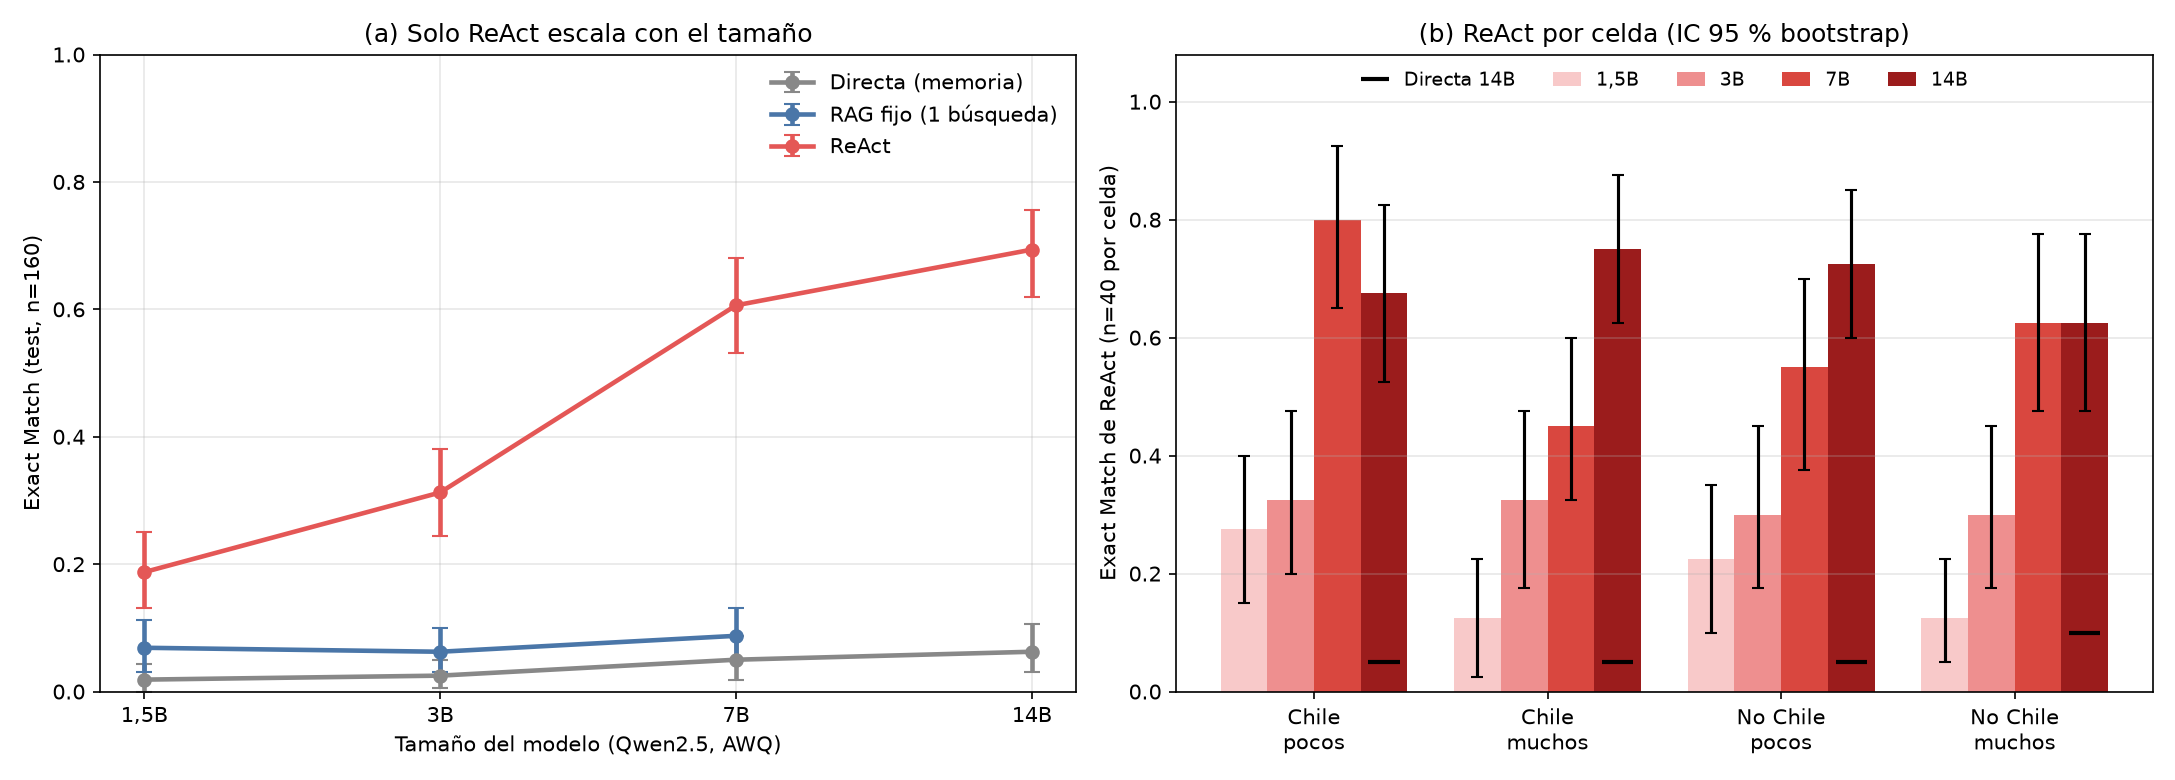

In [5]:
import matplotlib
matplotlib.use('Agg')   # evaluate.py ya fija Agg; la figura se guarda y se muestra como imagen
import matplotlib.pyplot as plt

ETIQUETA = {m: m.replace('.', ',') for m in MODELOS}           # "1.5B" -> "1,5B"
NOMBRE = {'directa': 'Directa (memoria)', 'rag': 'RAG fijo (1 búsqueda)', 'react': 'ReAct'}
COLOR = {'directa': '#888888', 'rag': '#4a76a8', 'react': '#e45756'}
# Un tono por modelo, más oscuro = más grande (4 tonos si están las trazas del 14B)
ROJOS = (['#f4a6a6', '#e45756', '#9b1c1c'] if len(MODELOS) <= 3
         else ['#f8c9c9', '#ee8f8f', '#d9473f', '#9b1c1c'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.2))

# (a) EM total vs. tamaño, una línea por condición
for cond in evaluate.ORDEN_CONDICIONES:
    f = total[total['condicion'] == cond].set_index('modelo').reindex(MODELOS)
    ax1.errorbar(range(len(MODELOS)), f['em'], yerr=[f['em'] - f['em_lo'], f['em_hi'] - f['em']],
                 marker='o', lw=2.2, capsize=4, color=COLOR[cond], label=NOMBRE[cond])
ax1.set_xticks(range(len(MODELOS)), [ETIQUETA[m] for m in MODELOS])
ax1.set_xlabel('Tamaño del modelo (Qwen2.5, AWQ)')
ax1.set_ylabel(f'Exact Match (test, n={int(total["n"].iloc[0])})')
ax1.set_title('(a) Solo ReAct escala con el tamaño')
ax1.legend(frameon=False)

# (b) ReAct por celda, una barra por modelo; Directa 7B como raya negra
react = celdas[celdas['condicion'] == 'react']
ancho = 0.8 / len(MODELOS)
for k, m in enumerate(MODELOS):
    f = react[react['modelo'] == m].set_index('grupo').reindex(evaluate.ORDEN_CELDAS)
    xs = [i + (k - (len(MODELOS) - 1) / 2) * ancho for i in range(len(evaluate.ORDEN_CELDAS))]
    ax2.bar(xs, f['em'], width=ancho, color=ROJOS[k % len(ROJOS)], label=ETIQUETA[m],
            yerr=[f['em'] - f['em_lo'], f['em_hi'] - f['em']], capsize=3)
mayor = MODELOS[-1]
d = celdas[(celdas['condicion'] == 'directa') & (celdas['modelo'] == mayor)] \
    .set_index('grupo').reindex(evaluate.ORDEN_CELDAS)
x_mayor = (len(MODELOS) - 1) / 2 * ancho
ax2.hlines(d['em'], [i + x_mayor - ancho / 3 for i in range(4)], [i + x_mayor + ancho / 3 for i in range(4)],
           color='black', lw=2, label=f'Directa {ETIQUETA[mayor]}')
ax2.set_xticks(range(4), ['Chile\npocos', 'Chile\nmuchos', 'No Chile\npocos', 'No Chile\nmuchos'])
ax2.set_ylabel(f'Exact Match de ReAct (n={int(react["n"].iloc[0])} por celda)')
ax2.set_title('(b) ReAct por celda (IC 95 % bootstrap)')
ax2.legend(frameon=False, ncol=len(MODELOS) + 1, loc='upper center', fontsize=9, handlelength=1.5)

for ax in (ax1, ax2):
    ax.grid(axis='y', alpha=0.3)
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax1.set_ylim(0, 1)
ax2.set_ylim(0, 1.08)   # espacio arriba para la leyenda en una fila
ax1.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig('resultados/figura_principal.png', dpi=150)
plt.close(fig)
display(Image('resultados/figura_principal.png'))

Gráfico de `evaluate.py` con las 3 condiciones por celda y modelo (`em_test.png`):

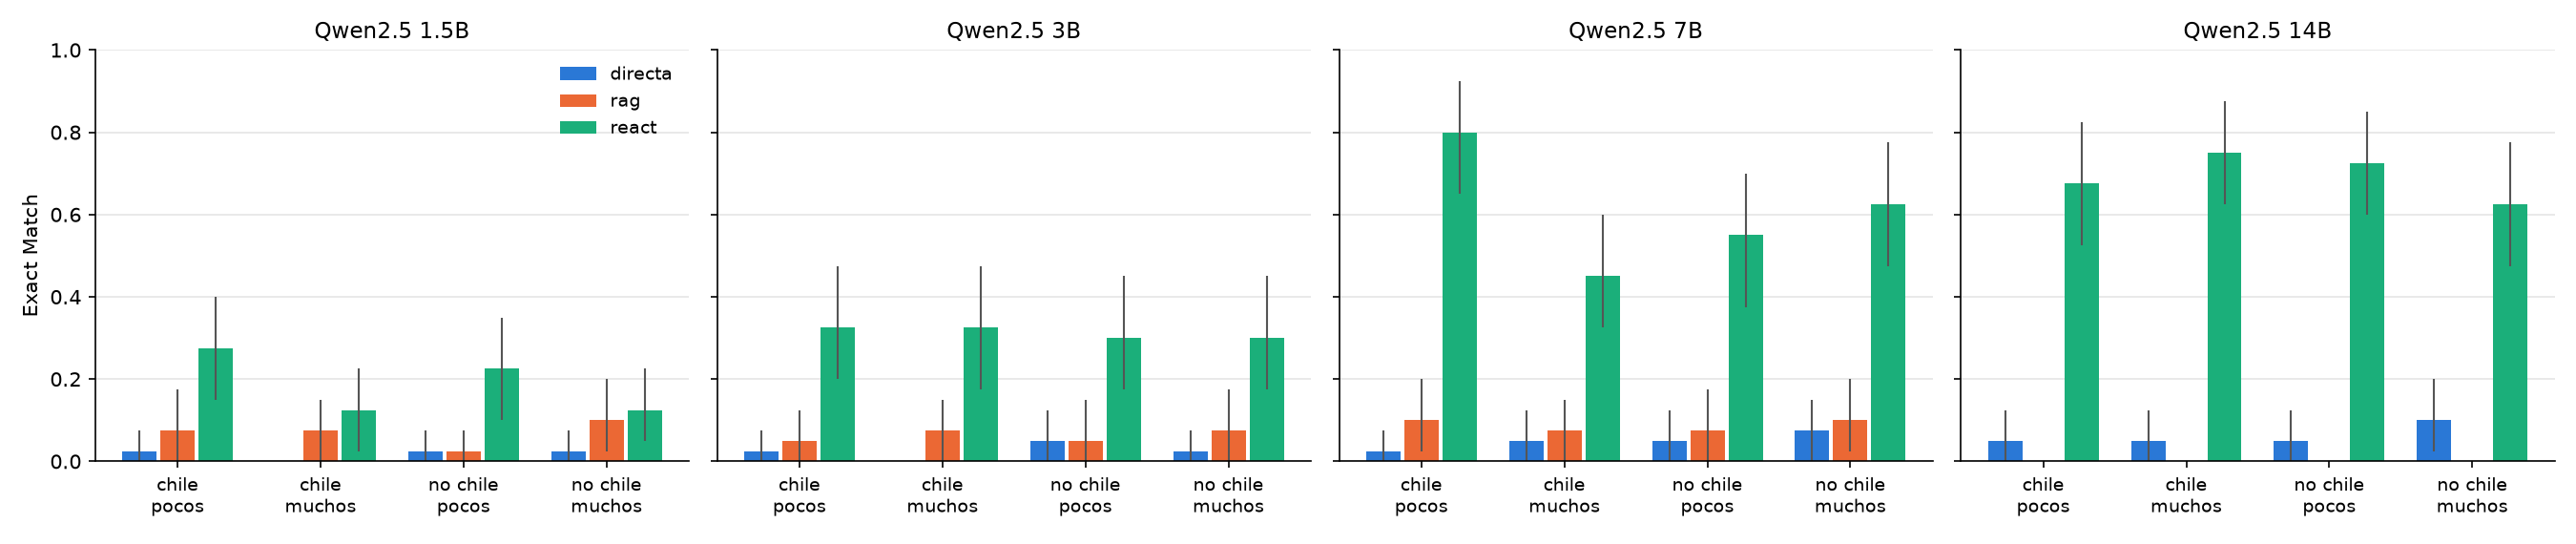

In [6]:
display(Image('resultados/em_test.png'))

## C. Corrida en vivo (opcional, GPU T4)

Corre las 3 condiciones con **Qwen2.5-1.5B** sobre **dev** (20 preguntas). Toma unos 5 minutos en total: instalar vLLM, descargar el modelo (~1,5 GB) y ~1 min de generación. Requiere Colab con GPU T4 (*Entorno de ejecución → Cambiar tipo de entorno*). Para correrla, cambia `CORRER_EN_VIVO` a `True`.

`correr.py` corre en un proceso aparte, porque vLLM no libera bien la GPU dentro del notebook. Reemplaza `resultados/trazas_1.5B_dev.jsonl`; antes se guarda una copia para comparar. Las páginas de Wikipedia salen de la caché; si el modelo busca algo nuevo, se consulta la API.

In [7]:
import shutil, tempfile
CORRER_EN_VIVO = False   # cambiar a True en Colab con GPU

respaldo = os.path.join(tempfile.gettempdir(), 'trazas_1.5B_dev_guardadas.jsonl')
if CORRER_EN_VIVO:
    shutil.copy('resultados/trazas_1.5B_dev.jsonl', respaldo)
    !pip install -q vllm==0.34.0
    !python correr.py 1.5B dev
    !python evaluate.py dev
else:
    print('Corrida en vivo desactivada (CORRER_EN_VIVO = False).')

Corrida en vivo desactivada (CORRER_EN_VIVO = False).


In [8]:
# Compara las respuestas nuevas con las guardadas (greedy: deberían coincidir casi todas).
import json
def respuestas(ruta):
    with open(ruta, encoding='utf-8') as f:
        return {(t['condicion'], t['id']): t['respuesta_modelo'] for t in map(json.loads, f)}

if CORRER_EN_VIVO:
    antes, ahora = respuestas(respaldo), respuestas('resultados/trazas_1.5B_dev.jsonl')
    iguales = sum(antes[k] == ahora.get(k) for k in antes)
    print(f'{iguales}/{len(antes)} respuestas idénticas a las de la corrida guardada')